In [ ]:
from google.colab import files

uploaded = files.upload()

Saving banking_dataset.csv to banking_dataset.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("banking_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (150, 8)


,Customer_ID,Age_Group,Occupation,Monthly_Income,Monthly_Expenses,Savings,Credit_Card_Spending,Loan_Amount
0,C001,26-35,Self-employed,61139.30,37800.26,23339.04,6477.38,623876.32
1,C002,56+,Salaried,43709.99,24121.43,19588.57,4626.40,85584.51
2,C003,36-45,Salaried,113598.60,66256.60,47342.00,21401.83,608822.32
3,C004,36-45,Salaried,75847.98,33345.03,42502.95,7008.25,433013.26
4,C005,18-25,Self-employed,20000.00,15027.26,4972.74,3495.80,770393.60


In [ ]:
df.info()
df.describe()
df.describe(include="object")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           150 non-null    object 
 1   Age_Group             150 non-null    object 
 2   Occupation            150 non-null    object 
 3   Monthly_Income        150 non-null    float64
 4   Monthly_Expenses      150 non-null    float64
 5   Savings               150 non-null    float64
 6   Credit_Card_Spending  150 non-null    float64
 7   Loan_Amount           150 non-null    float64
dtypes: float64(5), object(3)
memory usage: 9.5+ KB


,Customer_ID,Age_Group,Occupation
count,150,150,150
unique,150,5,2
top,C001,26-35,Salaried
freq,1,43,94


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Customer_ID             0
Age_Group               0
Occupation              0
Monthly_Income          0
Monthly_Expenses        0
Savings                 0
Credit_Card_Spending    0
Loan_Amount             0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print("Duplicate Customer IDs:", df["Customer_ID"].duplicated().sum())

Duplicate Customer IDs: 0


In [ ]:
numeric_columns = [
    "Monthly_Income",
    "Monthly_Expenses",
    "Savings",
    "Credit_Card_Spending",
    "Loan_Amount"
]

for col in numeric_columns:
    print(col, "negative values:", (df[col] < 0).sum())

Monthly_Income negative values: 0
Monthly_Expenses negative values: 0
Savings negative values: 0
Credit_Card_Spending negative values: 0
Loan_Amount negative values: 0


In [ ]:
print(df.dtypes)

Customer_ID              object
Age_Group                object
Occupation               object
Monthly_Income          float64
Monthly_Expenses        float64
Savings                 float64
Credit_Card_Spending    float64
Loan_Amount             float64
dtype: object


In [ ]:
df["Savings_Ratio"] = (
    df["Savings"] / df["Monthly_Income"]
)

In [ ]:
df["Expense_Ratio"] = (
    df["Monthly_Expenses"] / df["Monthly_Income"]
)

In [ ]:
df["Total_Spending"] = (
    df["Monthly_Expenses"] +
    df["Credit_Card_Spending"]
)

In [ ]:
df.head()

,Customer_ID,Age_Group,Occupation,Monthly_Income,Monthly_Expenses,Savings,Credit_Card_Spending,Loan_Amount,Savings_Ratio,Expense_Ratio,Total_Spending
0,C001,26-35,Self-employed,61139.30,37800.26,23339.04,6477.38,623876.32,0.381735,0.618265,44277.64
1,C002,56+,Salaried,43709.99,24121.43,19588.57,4626.40,85584.51,0.448149,0.551852,28747.83
2,C003,36-45,Salaried,113598.60,66256.60,47342.00,21401.83,608822.32,0.416748,0.583252,87658.43
3,C004,36-45,Salaried,75847.98,33345.03,42502.95,7008.25,433013.26,0.560370,0.439630,40353.28
4,C005,18-25,Self-employed,20000.00,15027.26,4972.74,3495.80,770393.60,0.248637,0.751363,18523.06


In [ ]:
df[
    [
        "Monthly_Income",
        "Monthly_Expenses",
        "Savings",
        "Credit_Card_Spending",
        "Loan_Amount",
        "Savings_Ratio",
        "Expense_Ratio",
        "Total_Spending"
    ]
].describe()

,Monthly_Income,Monthly_Expenses,Savings,Credit_Card_Spending,Loan_Amount,Savings_Ratio,Expense_Ratio,Total_Spending
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,61937.707133,35793.273733,26362.285067,7405.168933,388839.128200,0.428503,0.574352,43198.442667
std,22215.817122,17756.149548,14176.992224,4020.086270,242400.079026,0.156765,0.165714,20494.844042
min,20000.000000,8983.470000,0.000000,500.000000,7816.680000,0.000000,0.320920,10576.890000
25%,44999.730000,22725.600000,18044.522500,4461.917500,162935.775000,0.334563,0.447870,27616.837500
50%,60876.025000,33344.445000,24971.905000,6528.065000,388066.215000,0.437544,0.562456,41032.970000
75%,76376.947500,43006.780000,34430.457500,9624.257500,604888.287500,0.552130,0.665437,54220.865000
max,114745.070000,111344.990000,71294.610000,21401.830000,797699.600000,0.679080,1.189004,120757.510000


In [ ]:
df.groupby("Occupation")[
    [
        "Monthly_Income",
        "Monthly_Expenses",
        "Savings",
        "Credit_Card_Spending",
        "Savings_Ratio"
    ]
].mean()

,Monthly_Income,Monthly_Expenses,Savings,Credit_Card_Spending,Savings_Ratio
Occupation,,,,,
Salaried,62888.853936,35764.448617,27472.041170,7470.202234,0.440693
Self-employed,60341.139286,35841.658750,24499.480179,7296.005893,0.408039


In [ ]:
df.groupby("Age_Group")[
    [
        "Monthly_Income",
        "Monthly_Expenses",
        "Savings",
        "Savings_Ratio"
    ]
].mean()

,Monthly_Income,Monthly_Expenses,Savings,Savings_Ratio
Age_Group,,,,
18-25,57823.489730,36581.516216,21518.539730,0.382776
26-35,62882.944651,36810.192558,26594.725581,0.425092
36-45,66256.350937,37091.028750,29165.321250,0.447168
46-55,56037.409167,32770.333333,23267.074583,0.421835
56+,70151.377143,32802.554286,37348.822857,0.528594


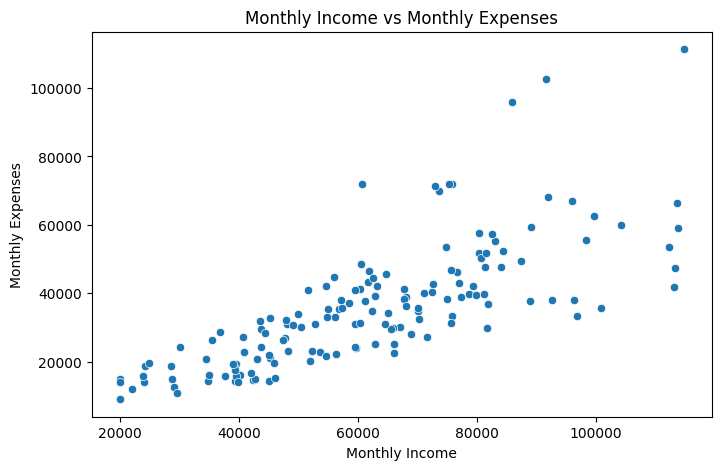

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Monthly_Income",
    y="Monthly_Expenses"
)

plt.title("Monthly Income vs Monthly Expenses")
plt.xlabel("Monthly Income")
plt.ylabel("Monthly Expenses")
plt.show()

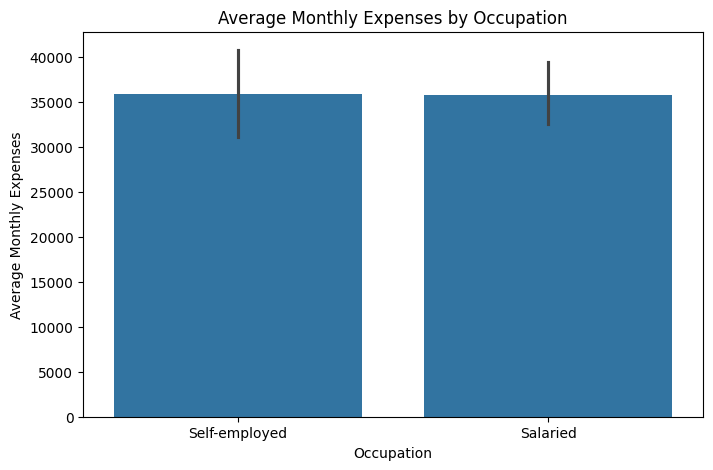

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Occupation",
    y="Monthly_Expenses"
)

plt.title("Average Monthly Expenses by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Average Monthly Expenses")
plt.show()

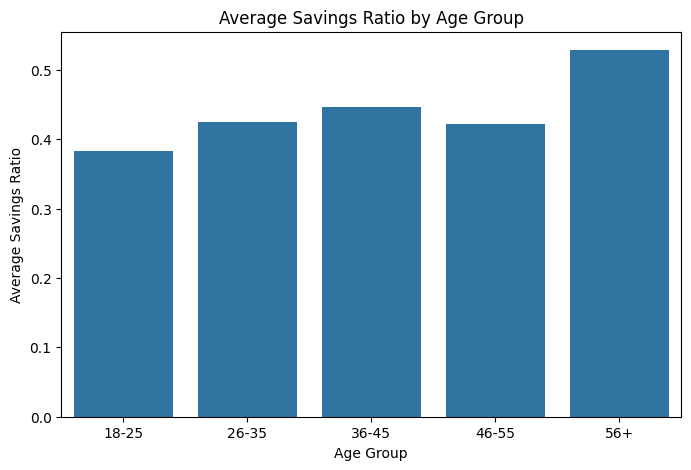

In [ ]:
age_savings = (
    df.groupby("Age_Group")["Savings_Ratio"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_savings,
    x="Age_Group",
    y="Savings_Ratio"
)

plt.title("Average Savings Ratio by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Savings Ratio")
plt.show()

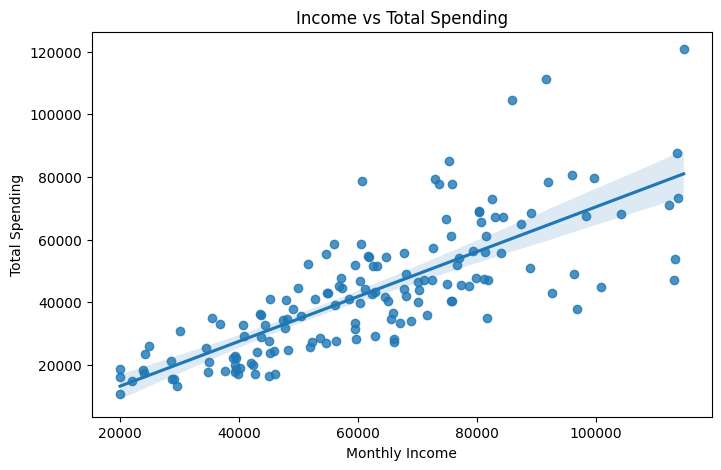

In [ ]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="Monthly_Income",
    y="Total_Spending"
)

plt.title("Income vs Total Spending")
plt.xlabel("Monthly Income")
plt.ylabel("Total Spending")
plt.show()

In [ ]:
correlation = df[
    [
        "Monthly_Income",
        "Monthly_Expenses",
        "Savings",
        "Credit_Card_Spending",
        "Loan_Amount"
    ]
].corr()

correlation

,Monthly_Income,Monthly_Expenses,Savings,Credit_Card_Spending,Loan_Amount
Monthly_Income,1.000000,0.752821,0.635998,0.629105,0.083725
Monthly_Expenses,0.752821,1.000000,-0.025658,0.620588,0.154412
Savings,0.635998,-0.025658,1.000000,0.210113,-0.050406
Credit_Card_Spending,0.629105,0.620588,0.210113,1.000000,0.057436
Loan_Amount,0.083725,0.154412,-0.050406,0.057436,1.000000


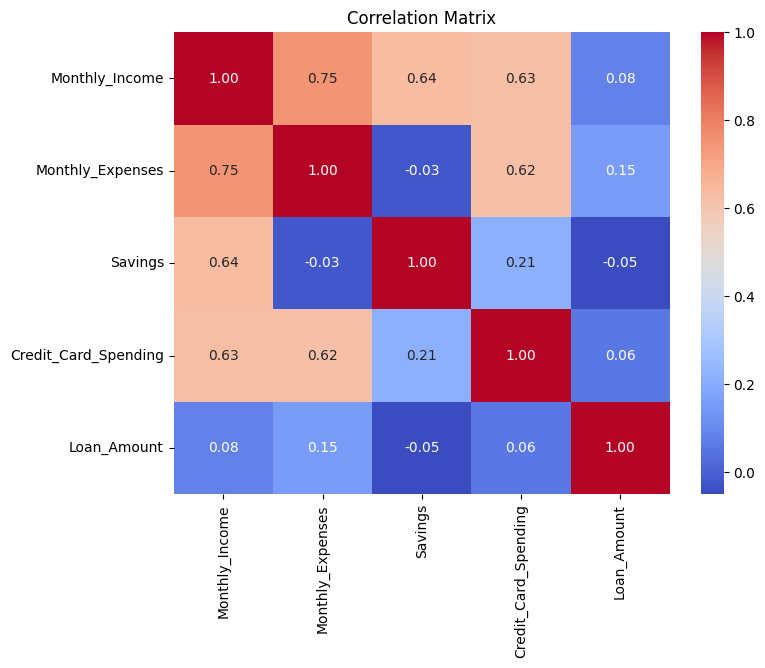

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [ ]:
print("Average Expense Ratio:",
      df["Expense_Ratio"].mean())

print("Standard Deviation:",
      df["Expense_Ratio"].std())

Average Expense Ratio: 0.5743516390765939
Standard Deviation: 0.16571420544323592


In [ ]:
threshold = (
    df["Expense_Ratio"].mean()
    + 2 * df["Expense_Ratio"].std()
)

unusual_customers = df[
    df["Expense_Ratio"] > threshold
]

unusual_customers[
    [
        "Customer_ID",
        "Age_Group",
        "Occupation",
        "Monthly_Income",
        "Monthly_Expenses",
        "Expense_Ratio",
        "Credit_Card_Spending"
    ]
]

,Customer_ID,Age_Group,Occupation,Monthly_Income,Monthly_Expenses,Expense_Ratio,Credit_Card_Spending
21,C022,18-25,Salaried,85811.63,96044.57,1.119249,8598.62
24,C025,26-35,Salaried,91672.78,102661.57,1.119870,8450.02
67,C068,46-55,Self-employed,75740.72,71856.32,0.948715,5799.93
71,C072,18-25,Salaried,75259.26,71985.84,0.956505,12963.97
76,C077,46-55,Self-employed,73677.43,69761.41,0.946849,8024.57
128,C129,18-25,Self-employed,72983.66,71275.26,0.976592,8100.38
138,C139,26-35,Salaried,60612.75,72068.81,1.189004,6483.85
146,C147,36-45,Self-employed,114745.07,111344.99,0.970368,9412.52


In [ ]:
occupation_summary = df.groupby("Occupation")[
    [
        "Monthly_Income",
        "Monthly_Expenses",
        "Savings",
        "Credit_Card_Spending",
        "Savings_Ratio",
        "Expense_Ratio"
    ]
].mean()

occupation_summary

,Monthly_Income,Monthly_Expenses,Savings,Credit_Card_Spending,Savings_Ratio,Expense_Ratio
Occupation,,,,,,
Salaried,62888.853936,35764.448617,27472.041170,7470.202234,0.440693,0.563861
Self-employed,60341.139286,35841.658750,24499.480179,7296.005893,0.408039,0.591961


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
X = df[["Monthly_Income"]]
y = df["Monthly_Expenses"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[36417.41094407 16046.00586473 39278.73201287 31465.63590307
 42769.8616867  19541.6703639  47980.2222834  48862.21920681
 22429.7746906  53979.5360663 ]


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 7542.102565581786
MSE : 101681361.21532504
RMSE: 10083.717628698507
R²  : 0.6004647099354952


In [ ]:
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 0.5912418961430408
Intercept: -791.3217294424394


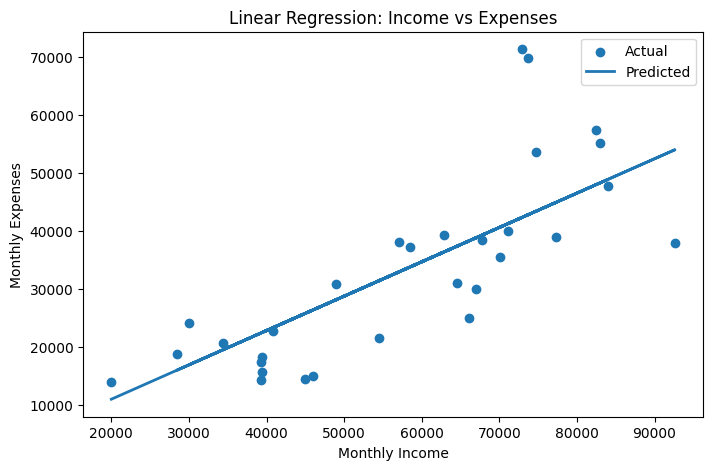

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test,
    y_test,
    label="Actual"
)

plt.plot(
    X_test,
    y_pred,
    linewidth=2,
    label="Predicted"
)

plt.title("Linear Regression: Income vs Expenses")
plt.xlabel("Monthly Income")
plt.ylabel("Monthly Expenses")
plt.legend()
plt.show()

KEY INSIGHTS :

1. Monthly income and monthly expenses show a positive relationship, indicating
   that customers with higher incomes generally tend to have higher expenses.
   However, the relationship is not perfect, showing that income alone does
   not completely determine spending behaviour.

2. The expense-to-income ratio varies considerably between customers. This
   indicates that customers with similar income levels can have substantially
   different spending patterns.

3. The savings ratio differs across age groups, suggesting that age is an
   important factor when analysing customer saving behaviour.

4. Salaried and self-employed customers show differences in their average
   income, expenses, savings, and credit-card spending. Therefore, occupation
   can be useful for customer segmentation.

5. Credit-card spending forms an additional component of customer spending
   and should be considered along with regular monthly expenses when analysing
   overall spending behaviour.

6. Several customers have unusually high expense-to-income ratios. These
   customers represent potential high-spending segments that may require
   additional financial-behaviour analysis.

7. The Linear Regression model provides a measurable estimate of how well
   monthly income can predict monthly expenses. The model's R² score of
   [INSERT R²] indicates that income explains approximately [INSERT R² × 100]%
   of the variation in monthly expenses in this dataset.

ACTION PLAN :

1. Use income together with expense-to-income and savings ratios when
   segmenting customers instead of relying on income alone.

2. Identify customers with unusually high spending relative to their income
   and provide appropriate financial-planning or budgeting services.

3. Develop different customer strategies for salaried and self-employed
   customers because their spending and saving patterns may differ.

4. Use savings behaviour to identify customers who may be suitable for
   savings, investment, or wealth-management products.

5. Monitor credit-card spending as part of overall customer spending
   behaviour, particularly for customers with high expense ratios.

6. Use the Linear Regression model as a supporting analytical tool for
   estimating expected expenses, while recognising that income alone cannot
   explain all customer spending behaviour.

7. Periodically update the analysis with new customer data to determine
   whether spending patterns change over time.

CONCLUSION :

This project analysed whether customer income determines spending behaviour
using income, expenses, savings, credit-card spending, loan information,
age group, and occupation.

The analysis found that income and expenses are related, but customers with
similar income levels can still exhibit different spending and saving
patterns. Differences across age groups and occupations further demonstrate
that customer financial behaviour is influenced by multiple factors.

The identification of unusually high expense-to-income customers shows the
importance of analysing spending behaviour relative to income rather than
looking at income alone. The Linear Regression model provided a quantitative
measure of the relationship between income and expenses and helped evaluate
how effectively income could predict monthly expenses.

Overall, the analysis indicates that income is an important factor in
understanding spending behaviour, but it should not be treated as the only
determinant. A combination of income, expenses, savings, credit-card usage,
occupation, and demographic characteristics provides a more complete view
of customer financial behaviour.